## Modélisation - Protocole temporel et enrichissement

Reprise de l'organisation des modélisations baseline et avancé.\
Mise en place d'un protocole temporel et évaluation progressive d'un enrichissement des variables par ablation.

La progression est structurée autour de :
- établir des ensembles d'expérience E et A avec:

| Expérience | Configuration | Enrichissement ajouté |
|:-----------|:--------------|:----------------------|
| E0 | Référence enrichie de base | Variables DVF + indicateurs INSEE + `creer_features_enrichi()` |
| E1 | E0 + historique parcellaire | Informations issues des ventes antérieures sur la parcelle `ajouter_historique_parcelle()`|
| E2 | E1 + historique de la voie | Informations historiques à l’échelle de la voie `ajouter_historique_voie()`|
| E3 | E2 + marché local | Indicateurs historiques du niveau de prix communal `ajouter_marche_local_historique()`|
| E4 | E3 + biens comparables | Références historiques de biens de même commune, type et classe de surface `ajouter_comparables()`|
| A0 | E4 + OpenStreetMap | Comptages et distances relatifs aux équipements et services de proximité `ajouter_features_equipements_osm()`|
- l'évaluation par ablation des différents enrichissement de features E0 ⇒ E4 + A0 OSM sur un modèle de référence
- la modélisation avancée et comparaison entre le dataset de référence E0 et un dataset enrichi retenu 
- l'adaptation des validations croisées et optimisations au protocole temporel
- l'interprétation du modèle final

Les résultats des modélisations baseline et avancées précédents (protocole aléatoire) sont conservés comme point de repère méthodologique. Les scores des deux démarches ne sont pas directement comparables, car le découpage et les configurations de données peuvent différer. On cherchera donc surtout à identifier les tendances qui se retrouvent d’une démarche à l’autre, puis à évaluer les enrichissements dans le cadre temporel.

In [3]:
#-----------------------------------------------------------------------------
## Imports et chargement des datasets
#-----------------------------------------------------------------------------

import os 
import sys
import pandas as pd
sys.path.append(os.path.abspath("..")) 

from src.models.train_model_enrichi import (
    preparer_donnees,
    preparer_donnees_temporel,
    entrainer_modeles,
    regression_ridge,
    entrainer_random_forest,
    entrainer_XGBRegressor,
    entrainer_CatBoostRegressor,
    valider_modeles_cv,
    valider_modeles_cv_temporel,
    optimiser_XGBRegressor_temporel,
    optimiser_XGBRegressor_2_temporel
)

from src.models.predict_model import predire_modele, calculer_metriques_modele

import numpy as np
import matplotlib.pyplot as plt
import shap

dvf_initial = pd.read_csv("../data/processed/dvf_initial_features_enrichies.csv", dtype={"code_commune": "string"})
dvf_nettoye = pd.read_csv("../data/processed/dvf_nettoye_features_enrichies.csv", dtype={"code_commune": "string"})
dvf_insee = pd.read_csv("../data/processed/dvf_features_enrichies_insee.csv", dtype={"code_commune": "string"})

print("DVF initial (avec prix extrêmes) :", dvf_initial.shape)
print("DVF nettoyé (sans prix extrêmes) :", dvf_nettoye.shape)
print("DVF enrichi avec les données INSEE :", dvf_insee.shape)
print("Prix extrêmes retirés :", len(dvf_initial) - len(dvf_nettoye))

DVF initial (avec prix extrêmes) : (115106, 33)
DVF nettoyé (sans prix extrêmes) : (110889, 33)
DVF enrichi avec les données INSEE : (110889, 45)
Prix extrêmes retirés : 4217


## Modélisation baseline
#### Référence features engineering de base + nouveaux ajouts

In [4]:
#-----------------------------------------------------------------------------
## Référence historique : Préparation des données
#-----------------------------------------------------------------------------

X_train_initial, X_test_initial, y_train_initial, y_test_initial = preparer_donnees(dvf_initial)
X_train_nettoye, X_test_nettoye, y_train_nettoye, y_test_nettoye = preparer_donnees(dvf_nettoye)
X_train_insee, X_test_insee, y_train_insee, y_test_insee = preparer_donnees(dvf_insee)

print("Train initial :", X_train_initial.shape)
print("Test initial :", X_test_initial.shape)

print("Train nettoyé :", X_train_nettoye.shape)
print("Test nettoyé :", X_test_nettoye.shape)

print("Train DVF + INSEE :", X_train_insee.shape)
print("Test DVF + INSEE :", X_test_insee.shape)


Train initial : (92084, 31)
Test initial : (23022, 31)
Train nettoyé : (88711, 31)
Test nettoyé : (22178, 31)
Train DVF + INSEE : (88711, 43)
Test DVF + INSEE : (22178, 43)


In [5]:
#-----------------------------------------------------------------------------
## Entraînement des modèles DummyRegressor et LinearRegression
#-----------------------------------------------------------------------------

dummy_initial, modele_lr_initial = entrainer_modeles(X_train_initial, y_train_initial)
dummy_nettoye, modele_lr_nettoye = entrainer_modeles(X_train_nettoye, y_train_nettoye)
_, modele_lr_insee = entrainer_modeles(X_train_insee, y_train_insee)

print("Les modèles sont entraînés.")

# ============================================================
# PRÉDICTIONS : DummyRegressor et LinearRegression

y_pred_dummy_initial = predire_modele(dummy_initial, X_test_initial)
y_pred_lr_initial = predire_modele(modele_lr_initial, X_test_initial)
y_pred_dummy_nettoye = predire_modele(dummy_nettoye, X_test_nettoye)
y_pred_lr_nettoye = predire_modele(modele_lr_nettoye, X_test_nettoye)
# DVF + INSEE
y_pred_lr_insee = predire_modele(modele_lr_insee, X_test_insee)
print("Les prédictions sont générées.")

# ============================================================
# MÉTRIQUES : DummyRegressor et LinearRegression

resultat_dummy_initial = calculer_metriques_modele(y_test_initial, y_pred_dummy_initial, "DummyRegressor", "Avant traitement des prix extrêmes")
resultat_lr_initial = calculer_metriques_modele(y_test_initial, y_pred_lr_initial, "LinearRegression", "Avant traitement des prix extrêmes")
resultat_dummy_nettoye = calculer_metriques_modele(y_test_nettoye, y_pred_dummy_nettoye, "DummyRegressor", "Après traitement des prix extrêmes")
resultat_lr_nettoye = calculer_metriques_modele(y_test_nettoye, y_pred_lr_nettoye, "LinearRegression", "Après traitement des prix extrêmes")
resultats_lr_insee = calculer_metriques_modele(y_test_insee, y_pred_lr_insee, "Régression linéaire", "DVF + INSEE")

comparaison_baselines = pd.concat([resultat_dummy_initial, resultat_lr_initial, resultat_dummy_nettoye, resultat_lr_nettoye, resultats_lr_insee], ignore_index=True)
display(comparaison_baselines.round(2))


Les modèles sont entraînés.
Les prédictions sont générées.


,Dataset,Modèle,MAE (€/m²),RMSE (€/m²),R²
0,Avant traitement des prix extrêmes,DummyRegressor,1327.15,3291.08,-0.00
1,Avant traitement des prix extrêmes,LinearRegression,1021.83,3027.40,0.15
2,Après traitement des prix extrêmes,DummyRegressor,1174.95,1520.96,-0.01
3,Après traitement des prix extrêmes,LinearRegression,803.03,1337.50,0.22
4,DVF + INSEE,Régression linéaire,826.40,1119.67,0.45


In [6]:
#-----------------------------------------------------------------------------
## Regression Ridge vs Regression linear
#-----------------------------------------------------------------------------

modele_ridge, meilleurs_parametres_ridge, mae_cv_ridge = regression_ridge(X_train_nettoye, y_train_nettoye)

# Réaliser les prédictions + Calculer les métriques du modèle Ridge sur les données de test
y_pred_ridge = predire_modele(modele_ridge, X_test_nettoye)
resultats_ridge = calculer_metriques_modele(y_test_nettoye, y_pred_ridge, "Ridge (régression linéaire régularisée)", "Dataset nettoyé")

# comparer les résultats de la régression linéaire et de Ridge
comparaison_regressions = pd.concat([resultat_lr_nettoye, resultats_ridge], ignore_index=True)
display(comparaison_regressions.round(2))


,Dataset,Modèle,MAE (€/m²),RMSE (€/m²),R²
0,Après traitement des prix extrêmes,LinearRegression,803.03,1337.50,0.22
1,Dataset nettoyé,Ridge (régression linéaire régularisée),801.13,1254.07,0.31


In [7]:
#-----------------------------------------------------------------------------
## Validation croisée : Régression Linéaire et Ridge
#-----------------------------------------------------------------------------

modeles_lr_ridge = {
    "Régression linéaire": modele_lr_nettoye,
    "Ridge": modele_ridge
}

resultats_cv_lr_ridge = valider_modeles_cv(modeles=modeles_lr_ridge, X_train=X_train_nettoye, y_train=y_train_nettoye, n_splits=5)
display(resultats_cv_lr_ridge.round(2))


,Modèle,Nombre de folds,MAE moyenne (€/m²),Écart-type (€/m²)
0,Régression linéaire,5,803.78,2.83
1,Ridge,5,802.27,2.78


## Ablation temporelle : E0 ⇒ E4 + A0 OSM


Les datasets E0 à E4 et A0 OSM sont comparés avec le même Random Forest de référence afin de mesurer l'apport des nouvelles familles de variables avant toute optimisation d'hyperparamètres.

Le découpage temporel est confié à `preparer_donnees_temporel` du script `train_model_enrichi`. La fonction trie les observations par `date_mutation`, réserve les dernières dates au test, vérifie l'absence de chevauchement temporel et retire ensuite `date_mutation` des variables explicatives retournées.

In [ ]:
#-----------------------------------------------------------------------------
## Expériences incrémentales : Feature Engineering
#-----------------------------------------------------------------------------

import os
import pandas as pd
import numpy as np

dossier_experiences = "../data/processed"

fichiers_experiences = {
    "E0 - Baseline": "dvf_features_enrichies_insee.csv",
    "E1 - + Historique parcelle": "experience_plus_historique_parcelle.csv",
    "E2 - + Historique parcelle + voie": "experience_plus_historique_parcelle_voie.csv",
    "E3 - + Marché local": "experience_plus_historique_parcelle_voie_marche_local.csv",
    "E4 - + Comparables": "experience_plus_historique_parcelle_voie_marche_local_comparables.csv",
    "A0 - + Équipements OSM": "dvf_nettoye_features_enrichies_osm.csv"
}

# Chargement des datasets
experiences = {}

for nom, fichier in fichiers_experiences.items():
    chemin = os.path.join(dossier_experiences, fichier)
    experiences[nom] = pd.read_csv(chemin, dtype={"code_commune": "string"})

#-----------------------------------------------------------------------------
## Contrôle des datasets E0 => E4 + A0 OSM
#-----------------------------------------------------------------------------

for nom, df in experiences.items():
    print(f"{nom} : {df.shape}")

n_lignes = {nom: len(df) for nom, df in experiences.items()}
assert len(set(n_lignes.values())) == 1, (f"Nombre de lignes incohérent entre expériences : {n_lignes}")

e0 = experiences["E0 - Baseline"]

for nom, df in experiences.items():
    assert np.allclose(e0["prix_m2"].to_numpy(), df["prix_m2"].to_numpy(), equal_nan=True), f"prix_m2 différent ou ordre des lignes différent pour {nom}"

print("E0 => E4 + A0 OSM : même nombre de lignes et même cible dans le même ordre.")

colonnes_osm_attendues = [
    "creches_500m",
    "ecoles_500m",
    "commerces_essentiels_500m",
    "restaurants_500m",
    "sante_500m",
    "transports_500m",
    "sports_loisirs_500m",
    "espaces_verts_500m",
    "distance_creches_min",
    "distance_ecoles_min",
    "distance_transports_min",
    "distance_commerces_essentiels_min",
    "distance_espaces_verts_min"
]

assert all(colonne in experiences["A0 - + Équipements OSM"].columns for colonne in colonnes_osm_attendues), "Certaines variables OSM attendues sont absentes du dataset A0."

print("Variables OSM présentes :", colonnes_osm_attendues)


E0 - Baseline : (110889, 45)
E1 - + Historique parcelle : (110889, 49)
E2 - + Historique parcelle + voie : (110889, 51)
E3 - + Marché local : (110889, 53)
E4 - + Comparables : (110889, 55)
A0 - + Équipements OSM : (110889, 68)
✓ E0 => E4 + A0 OSM : même nombre de lignes et même cible dans le même ordre.
✓ Variables OSM présentes : ['creches_500m', 'ecoles_500m', 'commerces_essentiels_500m', 'restaurants_500m', 'sante_500m', 'transports_500m', 'sports_loisirs_500m', 'espaces_verts_500m', 'distance_creches_min', 'distance_ecoles_min', 'distance_transports_min', 'distance_commerces_essentiels_min', 'distance_espaces_verts_min']


In [ ]:
#-----------------------------------------------------------------------------
## E0 => E4 + A0 OSM : Ablation du Feature Engineering
#-----------------------------------------------------------------------------

resultats_ablation = []

for nom_experience, df_exp in experiences.items():

    # Split temporel réalisé avec la fonction preparer_donnees_temporel()
    X_train_exp, X_test_exp, y_train_exp, y_test_exp = preparer_donnees_temporel(df_exp)

    modele_rf_exp = entrainer_random_forest(X_train_exp, y_train_exp)
    y_pred_exp = predire_modele(modele_rf_exp, X_test_exp)
    metriques_exp = calculer_metriques_modele(y_test_exp, y_pred_exp, "RandomForestRegressor", nom_experience,)

    resultats_ablation.append(metriques_exp)

resultats_ablation = pd.concat(resultats_ablation, ignore_index=True)


# Gain de MAE par rapport à E0.
mae_e0 = resultats_ablation.loc[resultats_ablation["Dataset"] == "E0 - Baseline", "MAE (€/m²)"].iloc[0]

resultats_ablation["Gain MAE vs E0 (%)"] = ((mae_e0 - resultats_ablation["MAE (€/m²)"]) / mae_e0 * 100 )

display(resultats_ablation.round(2))


,Dataset,Modèle,MAE (€/m²),RMSE (€/m²),R²,Gain MAE vs E0 (%)
0,E0 - Baseline,RandomForestRegressor,678.30,937.39,0.52,0.00
1,E1 - + Historique parcelle,RandomForestRegressor,654.60,918.32,0.54,3.49
2,E2 - + Historique parcelle + voie,RandomForestRegressor,654.76,919.14,0.54,3.47
3,E3 - + Marché local,RandomForestRegressor,649.73,914.05,0.54,4.21
4,E4 - + Comparables,RandomForestRegressor,649.15,914.90,0.54,4.30
5,A0 - + Équipements OSM,RandomForestRegressor,649.93,916.23,0.54,4.18


Lecture de l'ablation



L’ablation montre que l’ajout de variables n’améliore pas nécessairement le résultat à chaque étape. Avec le Random Forest de référence, l’historique parcellaire fait passer la MAE de 678,30 à 654,60 €/m², soit une baisse de 23,70 €/m² (3,49 %). L’ajout de l’historique de voie ne produit ensuite pas de gain supplémentaire dans cette configuration. Les indicateurs de marché local et les comparables réduisent encore modestement la MAE, jusqu’à 649,15 €/m² pour E4.

A0 atteint 649,93 €/m² : cette configuration reste meilleure que la référence E0, mais elle ne dépasse pas E4 dans cette ablation menée avec un Random Forest. On ne peut donc pas conclure que l’ajout d’OSM constitue, à lui seul, le meilleur enrichissement de cette séquence.

A0 est néanmoins conservé pour la comparaison multi-modèles : l’objectif est alors de tester cette configuration complète avec plusieurs algorithmes, et non d’affirmer qu’elle est la meilleure variante possible de toutes les familles de variables. Les résultats suivants permettront de vérifier si son intérêt se retrouve au-delà du Random Forest.

In [10]:
#-----------------------------------------------------------------------------
## Sélection du dataset enrichi pour la suite
#-----------------------------------------------------------------------------

# Pour ce test OSM, on évalue directement A0 après l'ablation.
experience_retenue = "A0 - + Équipements OSM"

dvf_enrichi = experiences[experience_retenue]


# Split temporel réalisé avec la fonction preparer_donnees_temporel()
X_train_enrichi, X_test_enrichi, y_train_enrichi, y_test_enrichi = preparer_donnees_temporel(dvf_enrichi)

print("Dataset enrichi retenu :", experience_retenue)
print("Dataset :", dvf_enrichi.shape)
print("Train enrichi :", X_train_enrichi.shape)
print("Test enrichi :", X_test_enrichi.shape)


Dataset enrichi retenu : A0 - + Équipements OSM
Dataset : (110889, 68)
Train enrichi : (89662, 65)
Test enrichi : (21227, 65)


## Dataset de référence 

E0 correspond au dataset de référence : DVF nettoyé + feature engineering classique, sans les nouvelles features historiques, de marché, de comparables et OSM ajoutées dans les expériences suivantes.

In [11]:
#-----------------------------------------------------------------------------
## Dataset de référence pour la comparaison
#-----------------------------------------------------------------------------

dvf_reference = experiences["E0 - Baseline"]

# Même protocole temporel que pour les expériences E0 => E4 + A0 OSM.
# Split temporel réalisé avec la fonction preparer_donnees_temporel()
X_train_reference, X_test_reference, y_train_reference, y_test_reference = preparer_donnees_temporel(dvf_reference)

print("Dataset de référence :", dvf_reference.shape)
print("Train référence :", X_train_reference.shape)
print("Test référence :", X_test_reference.shape)


Dataset de référence : (110889, 45)
Train référence : (89662, 42)
Test référence : (21227, 42)


## Modélisation avancée — dataset de référence


In [ ]:
#-----------------------------------------------------------------------------
## Entraînement du Random Forest - Dataset de référence
#-----------------------------------------------------------------------------

modele_rf_reference = entrainer_random_forest(X_train_reference, y_train_reference)
# Prédictions : Random Forest
y_pred_rf_reference = predire_modele(modele_rf_reference, X_test_reference)
# Métriques : Random Forest
resultats_rf_reference = calculer_metriques_modele(y_test_reference, y_pred_rf_reference, "RandomForestRegressor", "E0 - Dataset de référence")

#-----------------------------------------------------------------------------
## Entraînement DU XGBRegressor - Dataset de référence
#-----------------------------------------------------------------------------

modele_xgb_reference = entrainer_XGBRegressor(X_train_reference, y_train_reference)
# Prédictions : XGBRegressor
y_pred_xgb_reference = predire_modele(modele_xgb_reference, X_test_reference)
# Métriques : XGBRegressor
resultats_xgb_reference = calculer_metriques_modele(y_test_reference, y_pred_xgb_reference, "XGBRegressor", "E0 - Dataset de référence")


#-----------------------------------------------------------------------------
## Entraînement du CatBoostRegressor - Dataset de référence
#-----------------------------------------------------------------------------

modele_catboost_reference = entrainer_CatBoostRegressor(X_train_reference, y_train_reference)
# Prédictions
y_pred_catboost_reference = predire_modele(modele_catboost_reference, X_test_reference)
# Métriques : CatBoostRegressor
resultats_catboost_reference = calculer_metriques_modele(y_test_reference, y_pred_catboost_reference, "CatBoostRegressor", "E0 - Dataset de référence")

comparaison_boosting_reference = pd.concat([resultats_rf_reference, resultats_xgb_reference, resultats_catboost_reference], ignore_index=True)
display(comparaison_boosting_reference.round(2))



,Dataset,Modèle,MAE (€/m²),RMSE (€/m²),R²
0,E0 - Dataset de référence,RandomForestRegressor,678.30,937.39,0.52
1,E0 - Dataset de référence,XGBRegressor,659.93,914.35,0.54
2,E0 - Dataset de référence,CatBoostRegressor,681.02,933.52,0.53


## Modélisation avancée — dataset enrichi



In [ ]:
#-----------------------------------------------------------------------------
## Entraînement du random forest - Dataset enrichi
#-----------------------------------------------------------------------------

modele_rf_enrichi = entrainer_random_forest(X_train_enrichi, y_train_enrichi)
## Prédictions : Random Forest
y_pred_rf_enrichi = predire_modele(modele_rf_enrichi, X_test_enrichi)
## Métriques : Random Forest
resultats_rf_enrichi = calculer_metriques_modele(y_test_enrichi, y_pred_rf_enrichi, "RandomForestRegressor", f"{experience_retenue}")


#-----------------------------------------------------------------------------
## Entraînement du XGBRegressor - Dataset enrichi
#-----------------------------------------------------------------------------

modele_xgb_enrichi = entrainer_XGBRegressor(X_train_enrichi, y_train_enrichi)
# Prédictions : XGBRegressor
y_pred_xgb_enrichi = predire_modele(modele_xgb_enrichi, X_test_enrichi)
# Métriques : XGBRegressor
resultats_xgb_enrichi = calculer_metriques_modele(y_test_enrichi, y_pred_xgb_enrichi, "XGBRegressor", f"{experience_retenue}")


#-----------------------------------------------------------------------------
## Entraînement du catboostregressor - dataset enrichi
#-----------------------------------------------------------------------------

modele_catboost_enrichi = entrainer_CatBoostRegressor(X_train_enrichi, y_train_enrichi)
# Prédictions
y_pred_catboost_enrichi = predire_modele(modele_catboost_enrichi, X_test_enrichi)
# Métriques : CatBoostRegressor
resultats_catboost_enrichi = calculer_metriques_modele(y_test_enrichi, y_pred_catboost_enrichi, "CatBoostRegressor", f"{experience_retenue}")

comparaison_boosting_enrichi = pd.concat([resultats_rf_enrichi, resultats_xgb_enrichi, resultats_catboost_enrichi], ignore_index=True)
display(comparaison_boosting_enrichi.round(2))


,Dataset,Modèle,MAE (€/m²),RMSE (€/m²),R²
0,A0 - + Équipements OSM,RandomForestRegressor,649.93,916.23,0.54
1,A0 - + Équipements OSM,XGBRegressor,621.01,881.10,0.58
2,A0 - + Équipements OSM,CatBoostRegressor,627.53,886.70,0.57


### Comparaison directe E0 vs dataset enrichi


In [ ]:
#-----------------------------------------------------------------------------
## Comparaison E0 vs dataset enrichi
#-----------------------------------------------------------------------------

comparaison_reference_enrichi = pd.concat([
        resultats_rf_reference,
        resultats_xgb_reference,
        resultats_catboost_reference,
        resultats_rf_enrichi,
        resultats_xgb_enrichi,
        resultats_catboost_enrichi
        ],
        ignore_index=True
)

display(comparaison_reference_enrichi.round(2))


,Dataset,Modèle,MAE (€/m²),RMSE (€/m²),R²
0,E0 - Dataset de référence,RandomForestRegressor,678.30,937.39,0.52
1,E0 - Dataset de référence,XGBRegressor,659.93,914.35,0.54
2,E0 - Dataset de référence,CatBoostRegressor,681.02,933.52,0.53
3,A0 - + Équipements OSM,RandomForestRegressor,649.93,916.23,0.54
4,A0 - + Équipements OSM,XGBRegressor,621.01,881.10,0.58
5,A0 - + Équipements OSM,CatBoostRegressor,627.53,886.70,0.57


## Synthèse de la comparaison E0/A0

Dans le protocole temporel, A0 obtient une MAE plus faible que E0 pour les trois modèles évalués. L’amélioration ne se limite donc pas à un seul algorithme : elle constitue un signal convergent en faveur de l’utilité prédictive de la configuration enrichie.

La section suivante précise l’ampleur de ce gain et identifie le modèle le plus performant dans cette comparaison.

La MAE diminue entre E0 et A0 pour les trois algorithmes : de 678,30 à 649,93 €/m² pour le Random Forest, de 659,93 à 621,01 €/m² pour XGBoost et de 681,02 à 627,53 €/m² pour CatBoost. Les gains sont respectivement de 28,37, 38,92 et 53,49 €/m².

Cette convergence renforce l’idée que la configuration enrichie contient une information utile, au-delà d’un effet propre à un seul modèle. Elle ne permet toutefois pas d’attribuer le gain à OSM seul, puisque A0 regroupe plusieurs enrichissements par rapport à E0. Dans cette comparaison, XGBoost présente la MAE la plus faible ; il constitue donc le candidat logique pour l’étape d’optimisation.

## Validation croisée temporelle des modèles avancés

La validation croisée est réalisée avec `TimeSeriesSplit` via `valider_modeles_cv_temporel`.\
Ce choix permet de comparer la stabilité des modèles dans un protocole cohérent avec la séparation temporelle retenue pour le jeu de test.

In [ ]:
#---------------------------------------------------------
## Validation croisée temporelle : E0
#-------------------------------------------------------

modeles_reference = {
    "RandomForest": modele_rf_reference,
    "XGBoost": modele_xgb_reference,
    "CatBoost": modele_catboost_reference
}

resultats_cv_reference = valider_modeles_cv_temporel(modeles=modeles_reference, X_train=X_train_reference, y_train=y_train_reference, n_splits=5)
display(resultats_cv_reference.round(2))


#---------------------------------------------------------
## Validation croisée temporelle : Dataset enrichi
#---------------------------------------------------------

modeles_enrichi = {
    "RandomForest": modele_rf_enrichi,
    "XGBoost": modele_xgb_enrichi,
    "CatBoost": modele_catboost_enrichi
}

resultats_cv_enrichi = valider_modeles_cv_temporel(modeles=modeles_enrichi, X_train=X_train_enrichi, y_train=y_train_enrichi, n_splits=5)
display(resultats_cv_enrichi.round(2))

,Modèle,Nombre de folds,MAE moyenne (€/m²),Écart-type (€/m²)
0,RandomForest,5,712.91,6.86
1,XGBoost,5,700.05,13.18
2,CatBoost,5,720.41,15.22


,Modèle,Nombre de folds,MAE moyenne (€/m²),Écart-type (€/m²)
0,RandomForest,5,694.93,6.37
1,XGBoost,5,663.42,17.57
2,CatBoost,5,671.58,15.15


La validation croisée confirme la tendance observée sur le test : la MAE moyenne diminue avec A0 pour les trois modèles. Les gains moyens sont d’environ 18,0 €/m² pour le Random Forest, 36,6 €/m² pour XGBoost et 48,8 €/m² pour CatBoost.

La variabilité n’évolue toutefois pas de façon uniforme. L’écart-type diminue légèrement pour le Random Forest (6,86 à 6,37 €/m²), augmente pour XGBoost (13,18 à 17,57 €/m²) et reste presque stable pour CatBoost (15,22 à 15,15 €/m²). L’enrichissement améliore donc la MAE moyenne, sans rendre systématiquement les résultats plus stables d’un pli à l’autre.

Cette lecture croisée invite à ne pas choisir un modèle sur la seule base d’une métrique : la MAE moyenne, la performance sur le test temporel et la variabilité doivent être considérées ensemble.

## 7. Optimisation de XGBoost


In [ ]:
#-----------------------------------------------------------------------------
## Optimisation du modèle XGBRegressor - Dataset de référence
#-----------------------------------------------------------------------------

modele_xgb_optimise_reference, meilleurs_parametres_xgb_reference, mae_cv_xgb_optimise_reference = optimiser_XGBRegressor_temporel(X_train_reference, y_train_reference)
# Prédictions
y_pred_xgb_optimise_reference = predire_modele(modele_xgb_optimise_reference, X_test_reference)
# Calcul des métriques
resultats_xgb_optimise_reference = calculer_metriques_modele(y_test_reference, y_pred_xgb_optimise_reference, "XGBoost optimisé", "E0 - Dataset de référence")

# Affichage des meilleurs paramètres
print("Meilleurs paramètres :", meilleurs_parametres_xgb_reference)
print("MAE CV optimisation 1 :", round(mae_cv_xgb_optimise_reference, 2))

#-----------------------------------------------------------------------------
## Optimisation du modèle XGBRegressor - Dataset enrichi
#-----------------------------------------------------------------------------

modele_xgb_optimise_enrichi, meilleurs_parametres_xgb_enrichi, mae_cv_xgb_optimise_enrichi = optimiser_XGBRegressor_temporel(X_train_enrichi, y_train_enrichi)
# Prédictions
y_pred_xgb_optimise_enrichi = predire_modele(modele_xgb_optimise_enrichi, X_test_enrichi)
# Calcul des métriques
resultats_xgb_optimise_enrichi = calculer_metriques_modele(y_test_enrichi, y_pred_xgb_optimise_enrichi, "XGBoost optimisé", f"{experience_retenue}")

# Affichage des meilleurs paramètres
print("Meilleurs paramètres :", meilleurs_parametres_xgb_enrichi)
print("MAE CV optimisation 1 :", round(mae_cv_xgb_optimise_enrichi, 2))


# Comparaison avant et après optimisation
comparaison_xgb = pd.concat([resultats_xgb_reference, resultats_xgb_optimise_reference, resultats_xgb_enrichi, resultats_xgb_optimise_enrichi], ignore_index=True)
display(comparaison_xgb.round(2))


Fitting 3 folds for each of 20 candidates, totalling 60 fits
Meilleurs paramètres : {'model__colsample_bytree': np.float64(0.7936880874433667), 'model__gamma': np.float64(0.12495298436110985), 'model__learning_rate': np.float64(0.06033121035675473), 'model__max_depth': 7, 'model__min_child_weight': 2, 'model__n_estimators': 797, 'model__reg_alpha': np.float64(0.17814891903848745), 'model__reg_lambda': np.float64(2.3136568830915083), 'model__subsample': np.float64(0.804426449876927)}
MAE CV optimisation 1 : 708.21
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Meilleurs paramètres : {'model__colsample_bytree': np.float64(0.7971969839497911), 'model__gamma': np.float64(0.07682049682839719), 'model__learning_rate': np.float64(0.026617343581537254), 'model__max_depth': 6, 'model__min_child_weight': 7, 'model__n_estimators': 795, 'model__reg_alpha': np.float64(0.012709563372047594), 'model__reg_lambda': np.float64(0.7157828539866089), 'model__subsample': np.float64(0.756285837

,Dataset,Modèle,MAE (€/m²),RMSE (€/m²),R²
0,E0 - Dataset de référence,XGBRegressor,659.93,914.35,0.54
1,E0 - Dataset de référence,XGBoost optimisé,646.60,904.33,0.55
2,A0 - + Équipements OSM,XGBRegressor,621.01,881.10,0.58
3,A0 - + Équipements OSM,XGBoost optimisé,619.34,878.14,0.58


In [ ]:
#-----------------------------------------------------------------------------
## Seconde optimisation du modèle xgbregressor - dataset de référence
#-----------------------------------------------------------------------------

modele_xgb_optimise_2_reference, meilleurs_parametres_xgb_2_reference, mae_cv_xgb_optimise_2_reference = optimiser_XGBRegressor_2_temporel(X_train_reference, y_train_reference)
# Prédictions
y_pred_xgb_optimise_2_reference = predire_modele(modele_xgb_optimise_2_reference, X_test_reference)
# Calcul des métriques
resultats_xgb_optimise_2_reference = calculer_metriques_modele(y_test_reference, y_pred_xgb_optimise_2_reference, "XGBoost optimisé 2", "E0 - Dataset de référence")

# Affichage des meilleurs paramètres
print("Meilleurs paramètres :", meilleurs_parametres_xgb_2_reference)
print("MAE CV optimisation 2 :", round(mae_cv_xgb_optimise_2_reference, 2))

#-----------------------------------------------------------------------------
## Seconde optimisation du modèle xgbregressor - dataset enrichi
#-----------------------------------------------------------------------------

modele_xgb_optimise_2_enrichi, meilleurs_parametres_xgb_2_enrichi, mae_cv_xgb_optimise_2_enrichi = optimiser_XGBRegressor_2_temporel(X_train_enrichi, y_train_enrichi)
# Prédictions
y_pred_xgb_optimise_2_enrichi = predire_modele(modele_xgb_optimise_2_enrichi, X_test_enrichi)
# Calcul des métriques
resultats_xgb_optimise_2_enrichi = calculer_metriques_modele(y_test_enrichi, y_pred_xgb_optimise_2_enrichi, "XGBoost optimisé 2", f"{experience_retenue}")

# Affichage des meilleurs paramètres
print("Meilleurs paramètres :", meilleurs_parametres_xgb_2_enrichi)
print("MAE CV optimisation 2 :", round(mae_cv_xgb_optimise_2_enrichi, 2))

# Comparaison des deux modèles
comparaison_xgb_optimise_2 = pd.concat([resultats_xgb_optimise_2_reference, resultats_xgb_optimise_2_enrichi], ignore_index=True)
display(comparaison_xgb_optimise_2.round(2))


Fitting 3 folds for each of 20 candidates, totalling 60 fits


Meilleurs paramètres : {'model__colsample_bytree': np.float64(0.8658367153944986), 'model__gamma': np.float64(0.07980735223012586), 'model__learning_rate': np.float64(0.05011044234247205), 'model__max_depth': 8, 'model__min_child_weight': 3, 'model__n_estimators': 780, 'model__reg_alpha': np.float64(0.24226839054973), 'model__reg_lambda': np.float64(2.7482106486374467), 'model__subsample': np.float64(0.8408939962171517)}
MAE CV optimisation 2 : 706.09
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Meilleurs paramètres : {'model__colsample_bytree': np.float64(0.8882811352534675), 'model__gamma': np.float64(0.06327387530778793), 'model__learning_rate': np.float64(0.05391965724838291), 'model__max_depth': 6, 'model__min_child_weight': 2, 'model__n_estimators': 739, 'model__reg_alpha': np.float64(0.2689067697356303), 'model__reg_lambda': np.float64(2.696784132164857), 'model__subsample': np.float64(0.8309538198583619)}
MAE CV optimisation 2 : 674.5


,Dataset,Modèle,MAE (€/m²),RMSE (€/m²),R²
0,E0 - Dataset de référence,XGBoost optimisé 2,640.39,899.87,0.56
1,A0 - + Équipements OSM,XGBoost optimisé 2,615.85,874.83,0.58


### Conclusion de l'optimisation

La seconde optimisation améliore la MAE de XGBoost dans les deux configurations.
- Sur E0, la deuxième optimisation atteint une MAE de **640,39 €/m²**, contre 659,93 €/m²  pour XGBoost standard, soit un gain de 19,54 €/m².
- Sur A0, la deuxième optimisation atteint une MAE de **615,85 €/m²**, contre 621,01 €/m² pour XGBoost standard, soit un gain supplémentaire de 5,16 €/m².

Le gain de l'optimisation 2 est plus marqué sur E0 que sur A0 : les variables enrichies améliorent déjà la performance de XGBoost standard, et la seconde optimisation apporte ensuite un gain supplémentaire plus modéré sur A0.

### 8. Tableau de synthèse final


In [ ]:
#------------------------------------------------
## Synthèse finale : E0 vs dataset enrichi
#------------------------------------------------

resultats_finaux = pd.concat([
        resultats_rf_reference,
        resultats_xgb_reference,
        resultats_catboost_reference,
        resultats_xgb_optimise_reference,
        resultats_xgb_optimise_2_reference,
        resultats_rf_enrichi,
        resultats_xgb_enrichi,
        resultats_catboost_enrichi,
        resultats_xgb_optimise_enrichi,
        resultats_xgb_optimise_2_enrichi
        ],
        ignore_index=True
)

display(resultats_finaux.sort_values("MAE (€/m²)").round(2))

,Dataset,Modèle,MAE (€/m²),RMSE (€/m²),R²
9,A0 - + Équipements OSM,XGBoost optimisé 2,615.85,874.83,0.58
8,A0 - + Équipements OSM,XGBoost optimisé,619.34,878.14,0.58
6,A0 - + Équipements OSM,XGBRegressor,621.01,881.10,0.58
7,A0 - + Équipements OSM,CatBoostRegressor,627.53,886.70,0.57
4,E0 - Dataset de référence,XGBoost optimisé 2,640.39,899.87,0.56
3,E0 - Dataset de référence,XGBoost optimisé,646.60,904.33,0.55
5,A0 - + Équipements OSM,RandomForestRegressor,649.93,916.23,0.54
1,E0 - Dataset de référence,XGBRegressor,659.93,914.35,0.54
0,E0 - Dataset de référence,RandomForestRegressor,678.30,937.39,0.52
2,E0 - Dataset de référence,CatBoostRegressor,681.02,933.52,0.53


### 9. Interprétation du meilleur modèle enrichi

Le modèle retenu pour l'analyse est XGBoost optimisé 2 sur A0. Ses résultats de test sont MAE = **615,85 €/m²**, RMSE = **874,83 €/m²** et R² = **0,58**.



,Variable_origine,Importance
2,code_commune,0.4056
5,comparable_median_price_m2,0.1507
49,previous_price_m2,0.0384
23,local_previous_median_price_m2,0.0257
20,has_nature_culture,0.0242
...,...,...
16,espaces_verts_500m,0.0024
31,mois_sin,0.0024
29,mois_cos,0.0024
6,creches_500m,0.0020


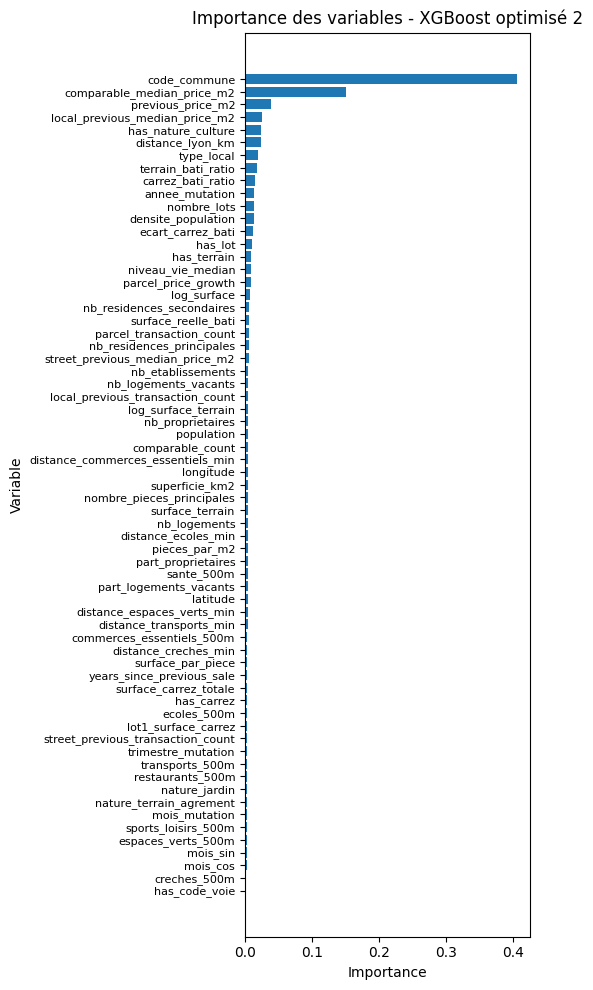

In [ ]:
#-----------------------------------------------------------------------------
## Importance des variables regroupées
#-----------------------------------------------------------------------------

preprocessor = modele_xgb_optimise_2_enrichi.named_steps["preprocessor"]
modele_xgb = modele_xgb_optimise_2_enrichi.named_steps["model"]
noms_variables = preprocessor.get_feature_names_out()

importance_variables = pd.DataFrame({"Variable": noms_variables, "Importance": modele_xgb.feature_importances_})

# Regrouper les modalités issues du OneHotEncoder
importance_variables["Variable_origine"] = (importance_variables["Variable"] .str.replace("num__", "", regex=False)
    .str.replace( r"^cat__code_commune_.*", "code_commune", regex=True ).str.replace(r"^cat__type_local_.*", "type_local", regex=True)
)

# Somme des importances par variable d'origine
importance_regroupee = (importance_variables.groupby("Variable_origine", as_index=False)["Importance"]
    .sum().sort_values("Importance", ascending=False)
)

display(importance_regroupee.round(4))

#-----------------------------------------------------------------------------
## Graphique de l'importance des variables regroupées
#-----------------------------------------------------------------------------

importance_graph = importance_regroupee.sort_values(by="Importance", ascending=True)

plt.figure(figsize=(6, 10))
plt.barh(importance_graph["Variable_origine"], importance_graph["Importance"])

plt.xlabel("Importance")
plt.ylabel("Variable")
plt.title("Importance des variables - XGBoost optimisé 2")

plt.tight_layout()
plt.tick_params(axis="y", labelsize=8)
plt.show()


Importance des variables:

**code_commune** domine toujours  (≈ 0,406), devant **comparable_median_price_m2** (≈ 0,151), **previous_price_m2** (≈ 0,038) et la **local_previous_median_price_m2** (≈ 0,026).

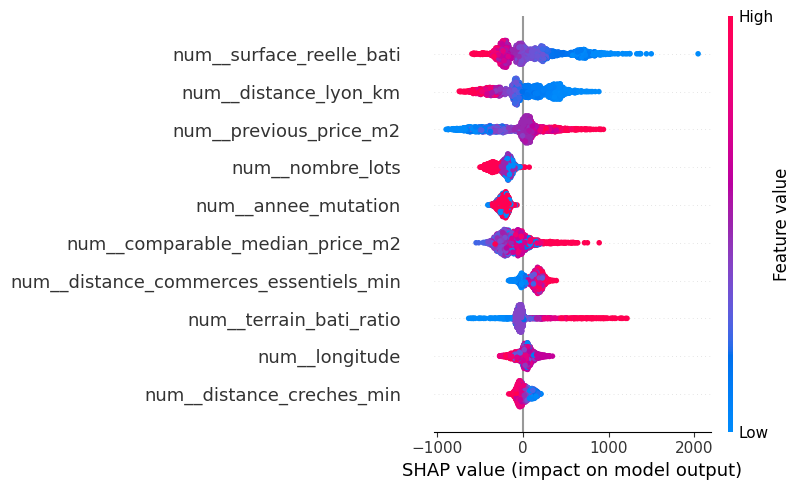

In [ ]:
#-----------------------------------------------------------------------------
## Interprétation SHAP des variables interprétables
#-----------------------------------------------------------------------------

# Transformer les données de test
X_test_transforme = preprocessor.transform(X_test_enrichi)

# Conversion en DataFrame avec les noms des variables
X_transforme_df = pd.DataFrame(X_test_transforme.toarray() if hasattr(X_test_transforme, "toarray") else X_test_transforme, columns=noms_variables)

# Supprimer les modalités de code_commune pour faciliter l'interprétation
colonnes_shap = [col for col in X_transforme_df.columns if not col.startswith("cat__code_commune_")]

# Garder uniquement les variables interprétables
X_shap = X_transforme_df[colonnes_shap].iloc[:2000]

# Récupérer les indices correspondants dans les données transformées
indices_shap = [X_transforme_df.columns.get_loc(col) for col in colonnes_shap]

# Calculer les valeurs SHAP sur l'ensemble des variables
explainer = shap.TreeExplainer(modele_xgb)
shap_values_complets = explainer.shap_values(X_transforme_df.iloc[:2000])

# Garder uniquement les valeurs SHAP des variables sélectionnées
shap_values = shap_values_complets[:, indices_shap]

# Graphique SHAP
shap.summary_plot(shap_values, X_shap, max_display=20, plot_size=(8, 5))


### Interprétation SHAP

La localisation reste déterminante : la commune ressort fortement dans l’importance globale, et la distance à Lyon présente toujours une relation nette avec les contributions SHAP. Les repères de prix, notamment le prix médian des comparables et l’historique de la parcelle, contribuent également fortement aux prédictions.

Les variables OSM apportent une lecture plus nuancée.
Pour les crèches, les distances les plus faibles tendent à être associées à des contributions plus positives. 

Pour les commerces essentiels, la relation est moins intuitive et pourrait refléter indirectement d’autres caractéristiques du territoire, comme des différences entre secteurs urbains denses et zones résidentielles périphériques. Toutefois, le graphique ne permet pas à lui seul de confirmer cette hypothèse ni de conclure que s’éloigner des commerces augmente le prix immobilier.

Au final, l’enrichissement permet d’améliorer les performances et d’exploiter davantage d’informations sur le logement et son environnement. L’interprétabilité nous aide à comprendre les signaux mobilisés par le modèle, tout en rappelant que ses prédictions restent des estimations, et non une explication exhaustive du prix immobilier.

## 10. Diagnostic des prédictions

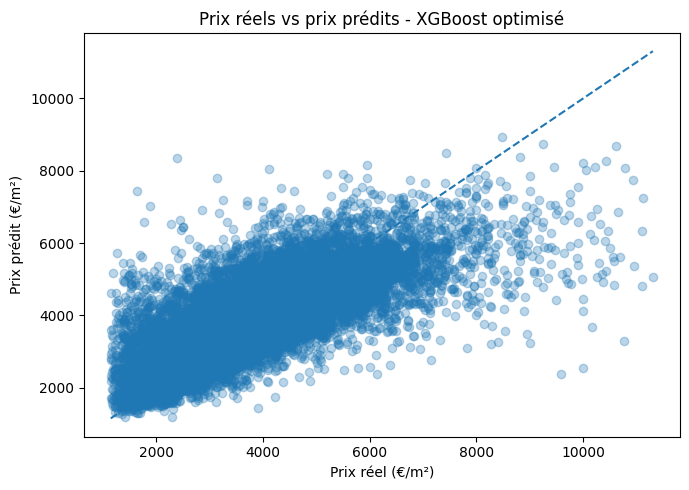

In [ ]:
#-----------------------------------------------------------------------------
## Comparaison des valeurs réelles et prédites
#-----------------------------------------------------------------------------

y_pred = modele_xgb_optimise_2_enrichi.predict(X_test_enrichi)

plt.figure(figsize=(7, 5))
plt.scatter(y_test_enrichi, y_pred, alpha=0.3)

minimum = min(y_test_enrichi.min(), y_pred.min())
maximum = max(y_test_enrichi.max(), y_pred.max())

plt.plot([minimum, maximum], [minimum, maximum], linestyle="--")
plt.xlabel("Prix réel (€/m²)")
plt.ylabel("Prix prédit (€/m²)")
plt.title("Prix réels vs prix prédits - XGBoost optimisé")
plt.tight_layout()
plt.show()


### Interprétation


In [ ]:
#-----------------------------------------------------------------------------
## Analyse des plus grandes erreurs
#-----------------------------------------------------------------------------

# Copie du jeu de test
analyse_erreurs = X_test_enrichi.copy()

# Ajout des prix réels et prédits
analyse_erreurs["prix_m2_reel"] = y_test_enrichi.values
analyse_erreurs["prix_m2_predit"] = y_pred

# Calcul de l'erreur absolue
analyse_erreurs["erreur_absolue"] = abs(analyse_erreurs["prix_m2_reel"] - analyse_erreurs["prix_m2_predit"])

# Sélection des 10 plus grandes erreurs
plus_grandes_erreurs = analyse_erreurs .sort_values("erreur_absolue", ascending=False) .head(10)

# Affichage des principales informations
display(plus_grandes_erreurs[["type_local", "surface_reelle_bati", "prix_m2_reel", "prix_m2_predit", "erreur_absolue"]].round(2))


,type_local,surface_reelle_bati,prix_m2_reel,prix_m2_predit,erreur_absolue
96522,Maison,65.0,10769.23,3280.129883,7489.10
99850,Appartement,55.0,10000.00,2545.530029,7454.47
110436,Maison,75.0,9588.70,2383.270020,7205.43
104697,Appartement,18.0,10166.67,3689.239990,6477.43
105734,Maison,64.0,11107.89,4824.240234,6283.65
98016,Maison,110.0,11307.27,5048.069824,6259.20
108083,Maison,105.0,2381.62,8364.599609,5982.98
92801,Maison,70.0,10000.00,4120.330078,5879.67
99701,Maison,130.0,1647.69,7427.839844,5780.15
108031,Maison,105.0,9000.00,3246.169922,5753.83


## 11. Conclusion

#### Synthèse et choix du modèle candidat

Deux enseignements se complètent. Le protocole aléatoire et le protocole temporel font ressortir une tendance similaire : XGBoost figure parmi les modèles les plus performants dans les expériences réalisées, tandis que la localisation reste structurante. Cette cohérence renforce la confiance dans la direction générale des résultats, sans rendre les scores des deux protocoles directement comparables.

Les résultats montrent que les enrichissements n’apportent pas tous le même gain. L’historique des transactions et les références de marché se révèlent particulièrement utiles, tandis que les données d’environnement apportent un complément plus variable. Même si les améliorations restent parfois modestes, les résultats sont encourageants.

Au final, les pistes d’enrichissement sont prometteuses et méritent d’être approfondies, en poursuivant l’évaluation rigoureuse de leur apport.

À ce stade, XGBoost optimisé 2 sur A0 est le **candidat prioritaire** parmi les expériences temporelles présentées, avec une MAE de 615,85 €/m² sur le test.

In [ ]:
#-----------------------------
## Enregistrer le modèle final
#-----------------------------

import os
import joblib

os.makedirs("../models", exist_ok=True)
output_model = "../models/modele_xgb_temporel_final.joblib"

joblib.dump(modele_xgb_optimise_2_enrichi, output_model)
print(f"Modèle enregistré dans {output_model}")

In [ ]:
# #-----------------------------------------------------------------------------
# # Vérification du chargement et de la prédiction du modèle final
# #-----------------------------------------------------------------------------

# # Chargement du modèle final
# modele_charge = joblib.load("../models/modele_xgb_temporel_final.joblib")

# # Prédiction sur une observation du jeu de test DVF + INSEE
# prediction_test = modele_charge.predict(X_test_enrichi.iloc[[0]])
# # Valeur réelle
# prix_reel = y_test_insee.iloc[0]

# # Calcul de l'erreur absolue
# erreur_absolue = abs(prix_reel - prediction_test[0])

# # Affichage des résultats
# print("Prix prédit :", round(prediction_test[0], 2), "€/m²")
# print("Prix réel :", round(prix_reel, 2), "€/m²")
# print("Erreur absolue :", round(erreur_absolue, 2), "€/m²")

### DataViz modèle

In [ ]:
import os
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap


sys.path.append(os.path.abspath(".."))

from src.models.train_model_enrichi import preparer_donnees_temporel

fichier_donnees = "../data/processed/dvf_nettoye_features_enrichies_osm.csv"
fichier_modele = "../models/modele_xgb_temporel_final.joblib"

# Charger les données et reproduire le découpage temporel utilisé pour le modèle.
dvf = pd.read_csv(fichier_donnees, dtype={"code_commune": "string"})
X_train, X_test, y_train, y_test = preparer_donnees_temporel(dvf)

# Charger le modèle déjà entraîné : pas besoin de le réentraîner pour faire ce graphique.
modele = joblib.load(fichier_modele)

print("Données de test :", X_test.shape)
print("Modèle chargé.")


Données de test : (21227, 61)
Modèle chargé.


#### Calcul des valeurs SHAP

In [ ]:

# Calcul des valeurs SHAP sur échantillon de 2 000 lignes.
n = min(2000, len(X_test))
X_echantillon = X_test.iloc[:n].copy()
prix_observe = pd.to_numeric(y_test.iloc[:n], errors="coerce").to_numpy()

preprocesseur = modele.named_steps["preprocessor"]
xgboost = modele.named_steps["model"]

X_prepare = preprocesseur.transform(X_echantillon)
noms_colonnes = preprocesseur.get_feature_names_out()

if hasattr(X_prepare, "toarray"):
    X_prepare = X_prepare.toarray()

X_prepare = pd.DataFrame(
    X_prepare,
    columns=noms_colonnes,
    index=X_echantillon.index
)

explainer = shap.TreeExplainer(xgboost)
valeurs_shap = np.asarray(explainer.shap_values(X_prepare))


if valeurs_shap.ndim == 3:
    valeurs_shap = valeurs_shap[:, :, 0]

print("Valeurs SHAP calculées :", valeurs_shap.shape)


Valeurs SHAP calculées : (2000, 337)


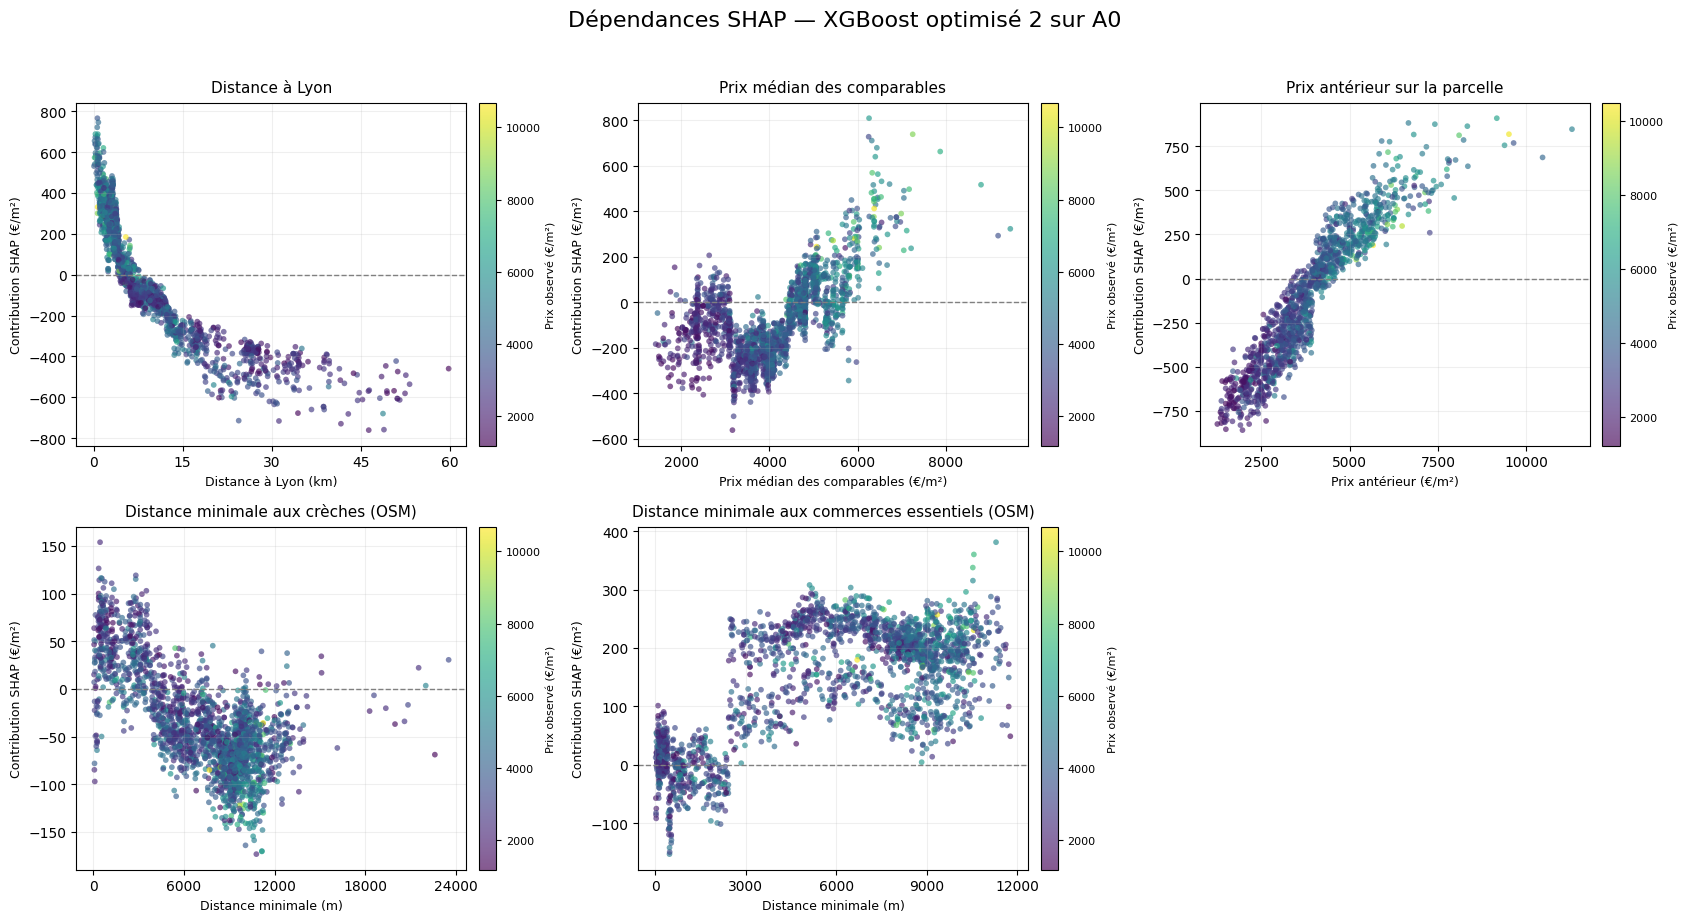

<Figure size 640x480 with 0 Axes>

In [ ]:
variables = [
    "distance_lyon_km",
    "comparable_median_price_m2",
    "previous_price_m2",
    "distance_creches_min",
    "distance_commerces_essentiels_min",
]

titres = {
    "distance_lyon_km": ("Distance à Lyon", "Distance à Lyon (km)"),
    "comparable_median_price_m2": ("Prix médian des comparables", "Prix médian des comparables (€/m²)"),
    "previous_price_m2": ("Prix antérieur sur la parcelle", "Prix antérieur (€/m²)"),
    "distance_creches_min": ("Distance minimale aux crèches (OSM)", "Distance minimale (m)"),
    "distance_commerces_essentiels_min": ("Distance minimale aux commerces essentiels (OSM)", "Distance minimale (m)"),
}


fig, axes = plt.subplots(2, 3, figsize=(17, 9))
axes = axes.ravel()

for i, variable in enumerate(variables):
    ax = axes[i]
    candidats = [
        col for col in X_prepare.columns
        if col == variable or col == f"num__{variable}" or col.endswith(f"__{variable}")
    ]
    col_transfo = candidats[0] if candidats else None

    if col_transfo is None or variable not in X_echantillon.columns:
        ax.axis("off")
        ax.text(0.5, 0.5, f"Variable indisponible\n{variable}", ha="center", va="center", transform=ax.transAxes)
        continue

    idx = X_prepare.columns.get_loc(col_transfo)
    x = pd.to_numeric(X_echantillon[variable], errors="coerce").to_numpy()
    y = valeurs_shap[:, idx]
    # X_test et y_test proviennent du même découpage et conservent le même ordre.
    prix_observe = pd.to_numeric(
        y_test.iloc[:n], errors="coerce"
    ).to_numpy()

    masque = np.isfinite(x) & np.isfinite(y) & np.isfinite(prix_observe)
    if masque.sum() == 0:
        ax.axis("off")
        ax.text(0.5, 0.5, f"Aucune valeur exploitable\n{variable}", ha="center", va="center", transform=ax.transAxes)
        continue

    points = ax.scatter(
        x[masque], y[masque], c=prix_observe[masque], cmap="viridis",
        s=17, alpha=0.65, linewidths=0,
    )
    ax.axhline(0, color="grey", linestyle="--", linewidth=1)
    titre, xlabel = titres[variable]
    ax.set_title(titre, fontsize=11, pad=8)
    ax.set_xlabel(xlabel, fontsize=9)
    ax.set_ylabel("Contribution SHAP (€/m²)", fontsize=9)
    ax.grid(True, alpha=0.2)
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    cbar = fig.colorbar(points, ax=ax, fraction=0.046, pad=0.03)
    cbar.set_label("Prix observé (€/m²)", fontsize=8)
    cbar.ax.tick_params(labelsize=8)

axes[-1].axis("off")
fig.suptitle("Dépendances SHAP — XGBoost optimisé 2 sur A0", fontsize=16, y=1.02)
fig.tight_layout()
plt.show()


plt.savefig("shap_dependances_ciblees_A0.png", dpi=220, bbox_inches="tight")
plt.show()
